# Bernstein-Vazirani Algorithm and its Qiskit Implementation

The Bernstein-Vazirani (BV) algorithm, described by Ethan Bernstein and Umesh Vazirani (1993/1997), finds a secret bit string hidden inside a "black box" (an **oracle**) with a **single** query, where any classical algorithm needs $n$ queries.

**Contents**
1. The problem
2. Classical solutions
3. The quantum algorithm (circuit and derivation)
4. Building the oracle: ancilla + CNOT vs. phase (Z) oracle
5. Worked example: $n=2$, $s=11$
6. Qiskit implementation
   - 6.1 Step-by-step circuit
   - 6.2 Reusable functions (bit-string or integer secret)
   - 6.3 Phase-oracle variant (no ancilla)
   - 6.4 Statevector check
   - 6.5 Classical vs. quantum query count
7. Running on real hardware
8. Summary and references

## 1. The problem

We are given an oracle for a Boolean function

$$ f_s : \{0,1\}^n \rightarrow \{0,1\}, \qquad f_s(x) = s \cdot x \pmod 2 = s_0 x_0 \oplus s_1 x_1 \oplus \dots \oplus s_{n-1} x_{n-1} $$

i.e. $f_s$ takes the bitwise AND of the input $x$ with a fixed secret string $s$ and returns the parity (XOR) of the result. We know $f$ has this form, but we do not know $s$.

**Task:** find $s$ using as few calls to $f_s$ as possible.

> Note: some texts phrase the problem as "$f$ returns 1 for exactly one string $s$". That is a different (search) problem. In BV, $f_s(x) = 1$ for *half* of all inputs (whenever $s \neq 0$); what is hidden is the linear structure, not a single marked item.

## 2. Classical solutions

**Approach 1 – guess-and-check.** If the box only told us "yes/no, $x = s$", we would have to try all numbers $0 \dots 2^n - 1$: exponentially many queries.

**Approach 2 – use the parity structure.** Because the box computes $s \cdot x \bmod 2$, we can query it with the $n$ unit strings $2^0, 2^1, \dots, 2^{n-1}$, each revealing one bit:

$$
\begin{aligned}
f_s(100\dots0) &= s_0 \\
f_s(010\dots0) &= s_1 \\
&\ \ \vdots \\
f_s(000\dots1) &= s_{n-1}
\end{aligned}
$$

Each classical query returns only one bit of information, so $n$ queries are necessary and sufficient.

**Quantum:** Bernstein-Vazirani recovers all of $s$ with **one** query, independent of $n$ (using $\mathcal{O}(n)$ gates).

## 3. The quantum algorithm

<img src="images/vazirani1.jpeg" width="300">

Here $Q_f$ is the **phase oracle** (the same kind of query as in the Deutsch-Jozsa algorithm, now on $n$ qubits):

$$ Q_f \lvert x \rangle = (-1)^{f(x)} \lvert x \rangle $$

The algorithm:

<ol>
    <li> Initialise the input register to zero:
    $$\lvert \psi_1 \rangle = \lvert 0 \rangle^{\otimes n} $$ </li><p></p>
    <li> Apply $H^{\otimes n}$ to get a uniform superposition of all $n$-bit strings:
    $$\lvert \psi_2 \rangle = \frac{1}{\sqrt{2^n}} \sum_{x \in \{0,1\}^{n} } \lvert x \rangle  $$
   </li><p></p>
    <li> Make one query $Q_f$. Because $(-1)^{s\cdot x} = \prod_i (-1)^{s_i x_i}$, the state factorises:
    $$
    \begin{aligned}
    \lvert \psi_3 \rangle &= \frac{1}{\sqrt{2^n}} \sum_{x} (-1)^{s\cdot x} \lvert x \rangle
    = \frac{1}{\sqrt{2^n}} \sum_{x} (-1)^{s_1 x_1} \cdots (-1)^{s_n x_n} \lvert x \rangle \\
    &= \frac{\lvert 0 \rangle + (-1)^{s_1} \lvert 1 \rangle }{\sqrt{2}} \otimes \cdots \otimes \frac{\lvert 0 \rangle + (-1)^{s_n} \lvert 1 \rangle }{\sqrt{2}}
    \end{aligned}
    $$
    Each qubit is now $\lvert + \rangle$ if $s_i = 0$ or $\lvert - \rangle$ if $s_i = 1$.
   </li><p></p>
    <li> Apply $H^{\otimes n}$ again. Since $H\lvert + \rangle = \lvert 0 \rangle$ and $H\lvert - \rangle = \lvert 1 \rangle$:
        $$ \lvert \psi_4 \rangle = \lvert s_1 \rangle \cdots \lvert s_n \rangle = \lvert s \rangle $$
   </li><p></p>
    <li> Measure all $n$ qubits (in the computational basis) to read out $s$ — deterministically, with probability 1.
    </li>
</ol>

An equivalent way to see step 4: the Hadamard transform satisfies
$$ H^{\otimes n} \lvert s \rangle = \frac{1}{\sqrt{2^n}} \sum_{x} (-1)^{s\cdot x} \lvert x \rangle , $$
so $\lvert\psi_3\rangle = H^{\otimes n}\lvert s\rangle$, and since $H^{\otimes n}$ is its own inverse, applying it once more yields $\lvert s \rangle$.

The speed-up ($n$ queries $\to$ 1) is modest and the problem is admittedly tailored to quantum computers, but at the time it was a landmark proof that quantum query advantage over classical (even probabilistic) algorithms is possible.

## 4. Building the oracle

There are two standard ways to implement $Q_f$; both appear in the code below.

**(a) Ancilla + CNOTs (phase kickback).** Add one ancilla qubit prepared in $\lvert - \rangle = H X \lvert 0 \rangle$. Implement the *bit* oracle $\lvert x \rangle \lvert y \rangle \mapsto \lvert x \rangle \lvert y \oplus f(x) \rangle$ by putting a $CX$ from input qubit $i$ to the ancilla for every $i$ with $s_i = 1$ (the CNOTs together XOR $s \cdot x$ into the ancilla). Since
$$ \lvert x \rangle \lvert - \rangle \;\mapsto\; (-1)^{f(x)} \lvert x \rangle \lvert - \rangle , $$
the result $f(x)$ is "kicked back" as a phase onto the input register and the ancilla is left unchanged.

**(b) Phase oracle with Z gates (no ancilla).** Since $(-1)^{s \cdot x} = \prod_{i:\, s_i = 1} (-1)^{x_i}$ and $Z\lvert x_i\rangle = (-1)^{x_i}\lvert x_i \rangle$, applying a $Z$ gate on every qubit $i$ with $s_i = 1$ implements $Q_f$ directly. With the surrounding Hadamards this is simply $HZH = X$ on those qubits — a nice sanity check that the output is $\lvert s \rangle$.

Variant (a) is the "textbook" form: it shows how a classical reversible function is turned into a phase oracle, a pattern reused in Deutsch-Jozsa, Simon and Grover.

## 5. Worked example: $n = 2$, $s = 11$

This follows the ion-trap realisation in [2], using the ancilla form of the oracle.

<img src="images/vazirani_ex1.jpeg"  width="300">

<ol>
    <li> Input registers initialised to zero, ancilla to one:
    $$\lvert \psi_1 \rangle = \lvert 0 0 \rangle \lvert 1 \rangle_a $$
   </li><p></p>
   <li> Apply Hadamard on all qubits:
    $$\lvert \psi_2 \rangle = \frac{1}{2} \left( \lvert 0 0 \rangle + \lvert 0 1 \rangle + \lvert 1 0 \rangle + \lvert 1 1 \rangle \right) \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle_a - \lvert 1 \rangle_a \right)  $$
   </li><p></p>
   <li> For $s=11$ the oracle is $Q_f = CX_{1a}CX_{2a}$:
    $$ \lvert \psi_3 \rangle = \frac{1}{2\sqrt{2}} \left[ \lvert 0 0 \rangle \left( \lvert 0 \oplus 0 \oplus 0 \rangle_a - \lvert 1 \oplus 0 \oplus 0 \rangle_a \right)+ \lvert 0 1 \rangle  \left( \lvert 0 \oplus 0 \oplus 1 \rangle_a - \lvert 1 \oplus 0 \oplus 1 \rangle_a \right) + \lvert 1 0 \rangle  \left( \lvert 0 \oplus 1 \oplus 0 \rangle_a - \lvert 1 \oplus 1 \oplus 0 \rangle_a \right) + \lvert 1 1 \rangle  \left( \lvert 0 \oplus 1 \oplus 1 \rangle_a - \lvert 1 \oplus 1 \oplus 1 \rangle_a \right)  \right] $$
   Thus
    $$
    \begin{aligned}
    \lvert \psi_3 \rangle &= \frac{1}{2\sqrt{2}} \left[ \lvert 0 0 \rangle \left( \lvert 0 \rangle_a - \lvert 1 \rangle_a \right) - \lvert 0 1 \rangle  \left( \lvert 0 \rangle_a - \lvert  1 \rangle_a \right) - \lvert 1 0 \rangle  \left( \lvert 0  \rangle_a - \lvert 1 \rangle_a \right) + \lvert 1 1 \rangle  \left( \lvert 0 \rangle_a - \lvert 1 \rangle_a \right)  \right] \\
    &= \frac{1}{2} \left( \lvert 0 0 \rangle - \lvert 0 1 \rangle - \lvert 1 0 \rangle + \lvert 1 1 \rangle \right) \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle_a - \lvert 1 \rangle_a \right)  \\
    &= \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)\frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)\frac{1}{\sqrt{2}} \left( \lvert 0 \rangle_a - \lvert 1 \rangle_a \right)
    \end{aligned}
    $$
   </li><p></p>
   <li> Apply Hadamard on all qubits:
        $$ \lvert \psi_4 \rangle = \lvert 1 \rangle \lvert 1 \rangle \lvert 1 \rangle_a $$
   </li><p></p>
   <li> Measuring the first two qubits gives the secret 2-bit string $s = 11$. (The ancilla always ends in $\lvert 1 \rangle$ and is not measured.)
   </li>
</ol>

## 6. Qiskit implementation

### Environment setup

#### Code walkthrough: backend setup

This cell prepares the machine the circuits will run on. It has nothing to do with the algorithm yet.

- **Why a helper module?** Older Qiskit tutorials used `Aer`, `BasicAer`, `execute()` and `IBMQ`. These were removed in Qiskit 1.x/2.x. The repo's own module `qiskit_backend_config.py` provides replacements for them, so code in the familiar style still works on current Qiskit.
- `sys.path.insert(0, ...)` adds the notebook's folder to Python's import search path, so `import qiskit_backend_config` finds the file sitting next to this notebook.
- The `from qiskit_backend_config import ...` line imports the whole compatibility toolkit. In this notebook we only really use two of them:
  - `get_backend(name)`: returns a backend object, i.e. a simulator or a real device.
  - `execute(circuit, backend, shots)`: compiles the circuit for that backend, runs it, and gives back a result object.
- `BACKEND_NAME = "qasm_simulator"` selects the local **Aer simulator in shot mode**. It runs the circuit like real hardware would: each run ("shot") ends with a measurement, and we get back how often each bit string appeared.
- `IBM_QUANTUM_TOKEN` is read from an environment variable. If it is empty, everything runs locally. The token is only needed in Section 7 (real hardware).
- **Expected output:** `Backend ready: LegacyAerSimulator('aer_simulator')`.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')

Backend ready: LegacyAerSimulator('aer_simulator')


#### Code walkthrough: imports

- `%matplotlib inline` is a Jupyter "magic" command. It makes plots appear directly under the cell.
- `numpy`: we use its random number generator in Section 6.5 to create random secrets.
- `matplotlib.pyplot`: the plotting library Qiskit uses to draw circuits and histograms.
- `QuantumCircuit`: the central Qiskit object. It holds a list of qubits, a list of classical bits, and the sequence of gates/measurements applied to them. `QuantumCircuit(5, 4)` means "5 qubits, 4 classical bits". Every qubit starts in $\lvert 0 \rangle$.
- `QuantumRegister` / `ClassicalRegister` let you create *named groups* of qubits/bits. The original notebooks used them. Here we pass plain numbers instead, but they are imported so you can experiment.
- `Statevector`: computes the **exact** quantum state of a circuit without measuring it. We use it in 6.4 to check the mathematics.
- `plot_histogram`: draws a bar chart of measurement counts.
- The last line prints the Qiskit version. This notebook was written for Qiskit 2.x.

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram

print('Qiskit version:', qiskit.__version__)

Qiskit version: 2.5.1


### 6.1 Step-by-step circuit

We first build the circuit by hand for a 6-bit secret. The algorithm needs $n+1$ qubits (the last is the ancilla) and $n$ classical bits.

**Bit ordering:** Qiskit is *little-endian* — qubit 0 is the right-most character of a bit string such as `'110101'`, and `get_counts()` prints classical bit 0 on the right. That is why we iterate over `reversed(s)` when placing the CNOTs: then the measured string reads exactly like `s`.

#### Code walkthrough: building the circuit by hand

Each block of code corresponds to one step of the derivation in Section 3. Compare them side by side.

**Setup**
- `s = '110101'` is the secret. In a real problem we would *not* know it; here we need it to *build* the oracle.
- `n = len(s)` gives `6` input qubits.
- `QuantumCircuit(n + 1, n)` creates **7 qubits** (indices 0–5 are the input register, index 6 is the ancilla) and **6 classical bits** to store the answer.

**Step 0: `circuit.x(n)`**
The X gate (quantum NOT) flips the ancilla from $\lvert 0 \rangle$ to $\lvert 1 \rangle$. We need $\lvert 1 \rangle$ because a Hadamard will then turn it into $\lvert - \rangle = \tfrac{1}{\sqrt2}(\lvert0\rangle - \lvert1\rangle)$, the state that makes phase kickback work (Section 4a).

**`circuit.barrier()`**
This is a vertical dashed line in the drawing. It changes nothing in the mathematics. It only (1) separates the steps visually and (2) stops the compiler from merging or cancelling gates across it.

**Step 1: `circuit.h(range(n + 1))`**
A Hadamard on every qubit. The 6 input qubits go from $\lvert 000000\rangle$ to an equal superposition of all $2^6 = 64$ bit strings ($\lvert\psi_2\rangle$), and the ancilla goes from $\lvert 1 \rangle$ to $\lvert - \rangle$.

**Step 2: the oracle (the loop)**
```python
for i, bit in enumerate(reversed(s)):
    if bit == '1':
        circuit.cx(i, n)
```
- `reversed(s)` reads the string from right to left. Qiskit numbers qubits **little-endian**: qubit 0 is the right-most character. So `enumerate(reversed(s))` yields pairs `(qubit index i, bit s_i)`:

  | `i` (qubit) | 0 | 1 | 2 | 3 | 4 | 5 |
  |---|---|---|---|---|---|---|
  | `bit` | 1 | 0 | 1 | 0 | 1 | 1 |

  so CNOTs are placed from qubits **0, 2, 4, 5** to the ancilla.
- `cx(i, n)` flips the ancilla when input qubit $i$ is $\lvert1\rangle$. All the CNOTs together flip it $s_0x_0 + s_1x_1 + \dots$ times, so the ancilla receives $y \oplus (s\cdot x)$.
- Because the ancilla is in $\lvert - \rangle$, a flip just multiplies the state by $-1$. Each input string $\lvert x\rangle$ therefore picks up the phase $(-1)^{s\cdot x}$. This gives $\lvert\psi_3\rangle$.

**Step 3: `circuit.h(range(n))`**
Hadamards on the **input qubits only**. This interference step turns $\lvert\psi_3\rangle$ into $\lvert s\rangle$ ($\lvert\psi_4\rangle$). The ancilla is skipped because we never measure it. It stays in $\lvert - \rangle$, unentangled with the inputs, so it does not affect the result.

**Step 4: `circuit.measure(range(n), range(n))`**
Measures qubit $i$ into classical bit $i$, for $i = 0 \dots 5$.

**`circuit.draw(output='mpl')`**
Draws the circuit. Check that you see: X on `q_6`, a column of H's, four CNOTs whose targets (⊕) are all on `q_6` with controls on `q_0, q_2, q_4, q_5`, another column of H's on `q_0`–`q_5`, then the measurements.

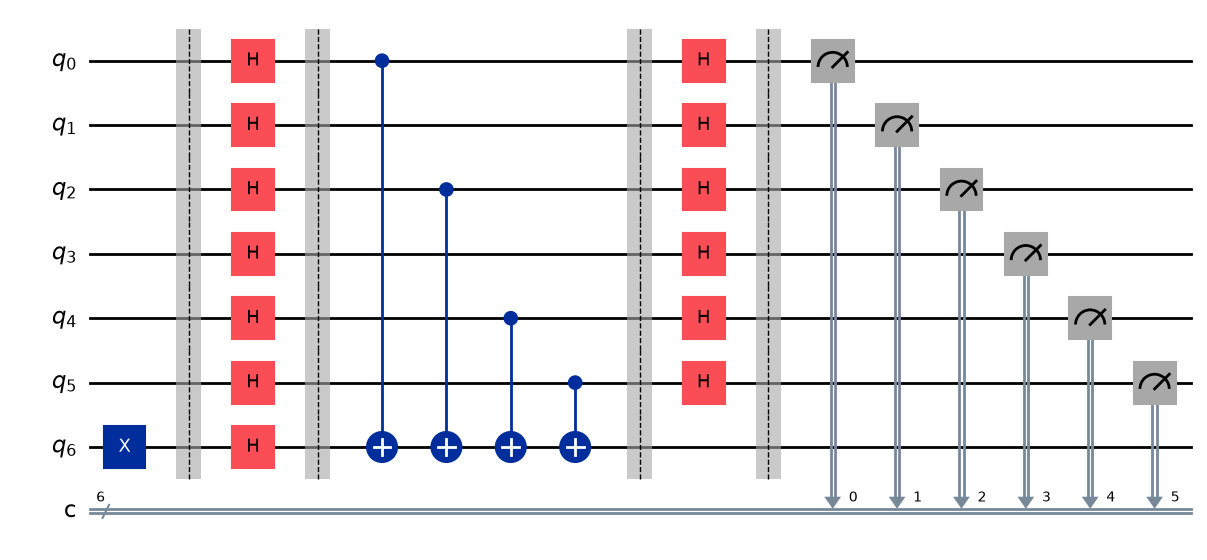

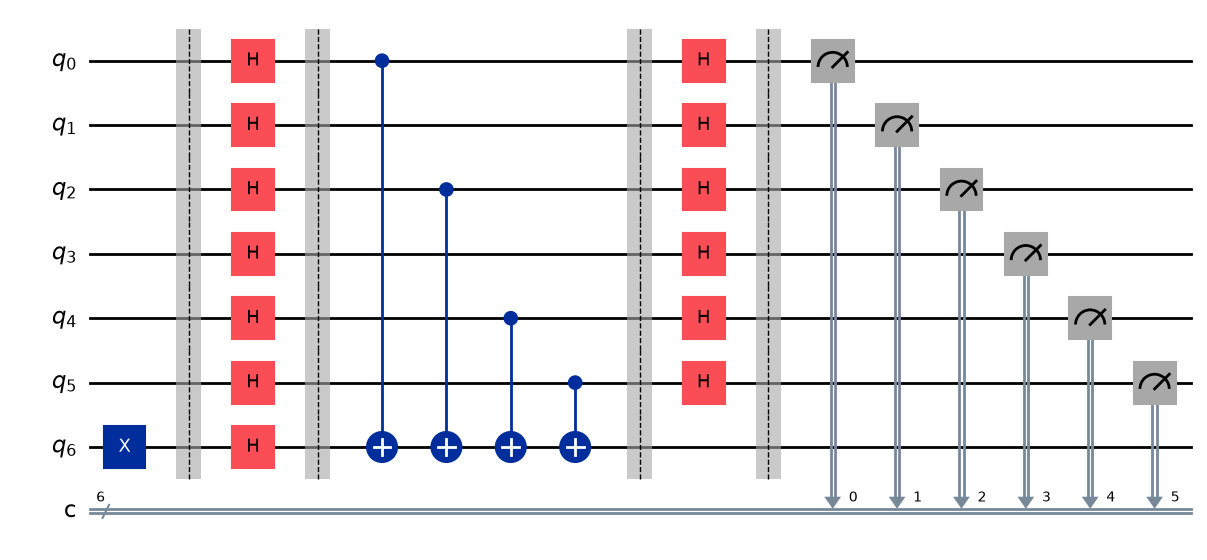

In [3]:
s = '110101'          # the secret string
n = len(s)
circuit = QuantumCircuit(n + 1, n)

# Step 0: ancilla (last qubit, index n) to |1>; inputs already start in |0>
circuit.x(n)
circuit.barrier()

# Step 1: Hadamard on all qubits -> uniform superposition, ancilla in |->
circuit.h(range(n + 1))
circuit.barrier()

# Step 2: oracle - CX from input qubit i to the ancilla wherever s_i = 1
for i, bit in enumerate(reversed(s)):
    if bit == '1':
        circuit.cx(i, n)
circuit.barrier()

# Step 3: Hadamard on the inputs again (the ancilla is not measured, so we may skip it)
circuit.h(range(n))
circuit.barrier()

# Step 4: measure the n input qubits
circuit.measure(range(n), range(n))

circuit.draw(output='mpl')

Because the output is deterministic, a **single shot** is enough:

#### Code walkthrough: running the circuit

- `get_backend('qasm_simulator')` gets a local shot-based simulator. It is the same kind of backend as `backend` above; we give it the clearer name `simulator`.
- `execute(circuit, backend=simulator, shots=1)` does three things:
  1. **transpiles** the circuit (rewrites it into gates the simulator supports),
  2. **runs** it `shots` times,
  3. returns a job; `.result()` waits for it to finish.
- `.get_counts()` returns a dictionary `{measured bit string: number of times seen}`.
- **Reading the bit string:** Qiskit prints classical bit 0 on the *right*. Because we placed the CNOTs using `reversed(s)`, the printed string reads exactly like `s`.
- **1 shot:** one run of the circuit, which contains **one query to the oracle**. The output `{'110101': 1}` already gives the whole secret. This is the quantum advantage: one query instead of six.
- **1000 shots:** only there to convince ourselves the result is **deterministic**. All 1000 runs give the same answer, so the histogram has a single bar at probability 1.0. (Many quantum algorithms, e.g. Grover's, are probabilistic and need repetition. Bernstein-Vazirani on ideal hardware does not.)
- `plot_histogram(counts_1000)` is the last expression in the cell, so Jupyter displays the chart.

1 shot   : {'110101': 1}
1000 shots: {'110101': 1000}


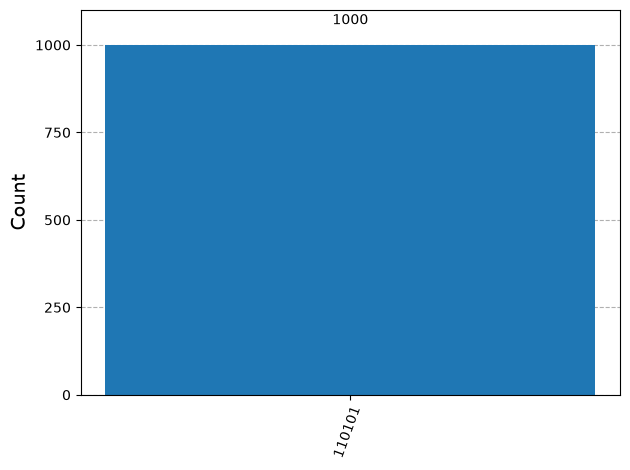

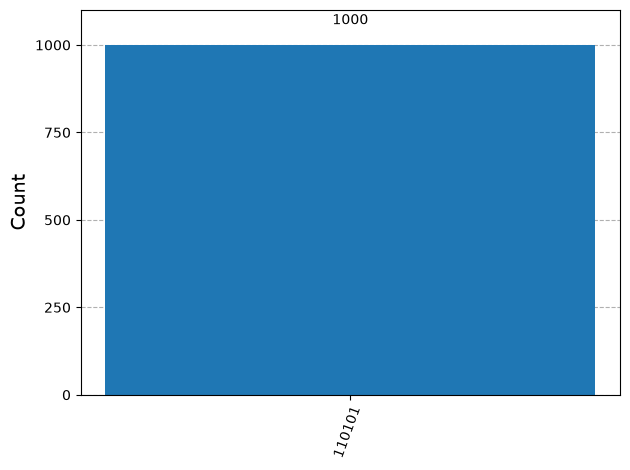

In [4]:
simulator = get_backend('qasm_simulator')
counts_1 = execute(circuit, backend=simulator, shots=1).result().get_counts()
print('1 shot   :', counts_1)

counts_1000 = execute(circuit, backend=simulator, shots=1000).result().get_counts()
print('1000 shots:', counts_1000)
plot_histogram(counts_1000)

100% of the shots return the secret `110101`.

### 6.2 Reusable functions

Now let us package the algorithm. `bv_oracle` builds either kind of oracle from Section 4, and `bernstein_vazirani` wraps it in the full algorithm. The secret may be passed as a bit string (`'1110'`) or as an integer with a width (`14, n=4`); in the integer form, bit $i$ of $s$ is tested with the mask `s & (1 << i)`.

#### Code walkthrough: reusable functions

This cell only **defines** three functions (it prints nothing). They turn the hand-built circuit of 6.1 into a general tool.

**`to_bitstring(s, n=None)`: normalises the input**
- If `s` is already a string like `'1110'`, it is returned unchanged.
- If `s` is an integer, it is converted to binary with `format(value, '0{n}b')`, which zero-pads to `n` digits. Examples: `to_bitstring(14, 4) → '1110'`, `to_bitstring(5, 4) → '0101'`.
- `s % 2**n` throws away any bits that don't fit in `n` qubits (the original `022-bernvaz` notebook did the same).
- If `n` is not given, `s.bit_length()` uses the minimum number of bits needed.

**`bv_oracle(s, kind='cnot')`: builds only the black box**
- We keep the oracle in its own circuit because in the real problem the oracle is *given to us*. The algorithm around it must not depend on what is inside.
- `kind='cnot'`: the circuit has `n + 1` qubits; for each `1` in `s` it adds `cx(i, n)` (Section 4a).
- `kind='phase'`: the circuit has `n` qubits; for each `1` in `s` it adds `z(i)` (Section 4b).
- It uses the same `reversed(s)` trick as before. Testing the character `s_i` is the string version of the integer test `s & (1 << i)` used in the original `.py` scripts. `1 << i` is the number with only bit $i$ set, and `&` is bitwise AND.
- `name=...` labels the box, which is handy if you draw it with `bv_oracle('101').draw('mpl')`.

**`bernstein_vazirani(s, n=None, kind='cnot', measure=True)`: the full algorithm**
1. Normalise `s` and get `n`.
2. Create the circuit: `n + 1` qubits if we use an ancilla, otherwise `n`. Classical bits are created only if we are going to measure.
3. If there is an ancilla: `x(n)` then `h(n)` puts it in $\lvert - \rangle$.
4. `h(inputs)`: superposition over all inputs.
5. `qc.compose(bv_oracle(s, kind), inplace=True)` pastes the oracle's gates into our circuit on the same qubit indices. This is the single query.
6. `h(inputs)`: interference, so the inputs become $\lvert s\rangle$.
7. **Ancilla clean-up:** `h(n)` turns $\lvert - \rangle$ back into $\lvert 1 \rangle$, and `x(n)` turns that into $\lvert 0 \rangle$. This is called *uncomputation*: we return scratch qubits to $\lvert 0 \rangle$ so they could be reused. It does not change the answer.
8. `measure(inputs, inputs)` measures qubit $i$ into bit $i$. Passing `measure=False` skips this, which we need for the statevector check in 6.4.

In [5]:
def to_bitstring(s, n=None):
    # Accept '1110' or (14, n=4); return the bit string (most significant bit first).
    if isinstance(s, str):
        return s
    if n is None:
        n = max(1, s.bit_length())
    return format(s % 2**n, f'0{n}b')


def bv_oracle(s, kind='cnot'):
    # kind='cnot'  : n+1 qubits, CX from each input with s_i = 1 onto the ancilla (qubit n)
    # kind='phase' : n qubits, Z on each input with s_i = 1 (no ancilla)
    n = len(s)
    width = n + 1 if kind == 'cnot' else n
    oracle = QuantumCircuit(width, name=f'Oracle(s={s})')
    for i, bit in enumerate(reversed(s)):
        if bit == '1':
            if kind == 'cnot':
                oracle.cx(i, n)
            else:
                oracle.z(i)
    return oracle


def bernstein_vazirani(s, n=None, kind='cnot', measure=True):
    s = to_bitstring(s, n)
    n = len(s)
    use_ancilla = (kind == 'cnot')
    qc = QuantumCircuit(n + 1 if use_ancilla else n, n if measure else 0)
    inputs = list(range(n))

    if use_ancilla:
        qc.x(n)
        qc.h(n)              # ancilla in |->
    qc.h(inputs)
    qc.barrier()
    qc.compose(bv_oracle(s, kind), inplace=True)
    qc.barrier()
    qc.h(inputs)
    if use_ancilla:
        qc.h(n)
        qc.x(n)              # return the ancilla to |0> (optional clean-up)
    if measure:
        qc.measure(inputs, inputs)
    return qc

Using an **integer** secret, $s = 14$ on 4 qubits (bit string `1110`):

#### Code walkthrough: integer secret $s = 14$

- `s_int = 14` is the secret as an ordinary number. `to_bitstring(14, 4)` gives `'1110'`, because $14 = 8 + 4 + 2 = 2^3 + 2^2 + 2^1$.
- `bernstein_vazirani(s_int, n=n_qubits)` builds the full circuit with the default CNOT oracle: 4 input qubits + 1 ancilla = 5 qubits.
- In the drawing you should see CNOTs from `q_1`, `q_2`, `q_3` to `q_4` and **none from `q_0`**, because bit 0 of 14 is `0`.
- `display(...)` is needed for the drawing because Jupyter only auto-shows the *last* expression of a cell. We want both the circuit and the histogram.
- The simulation with 1024 shots returns `{'1110': 1024}`. Converting back, `int('1110', 2) = 14`: we recovered the hidden integer.

s = 14 (bitstring = 1110)


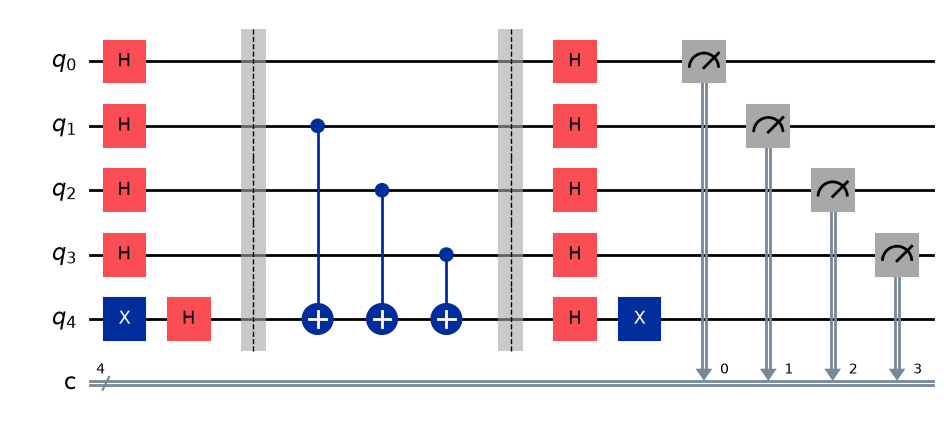

{'1110': 1024}


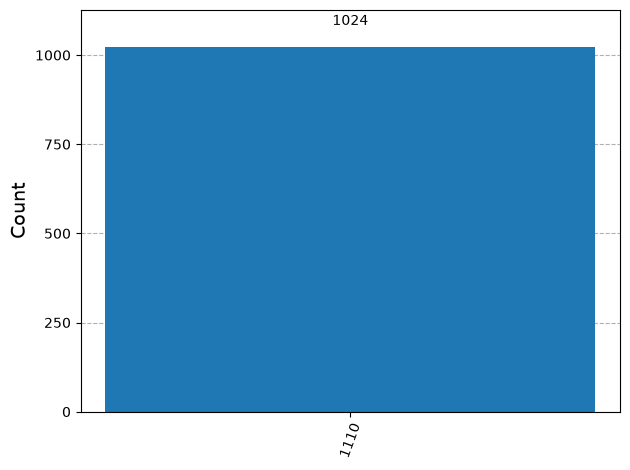

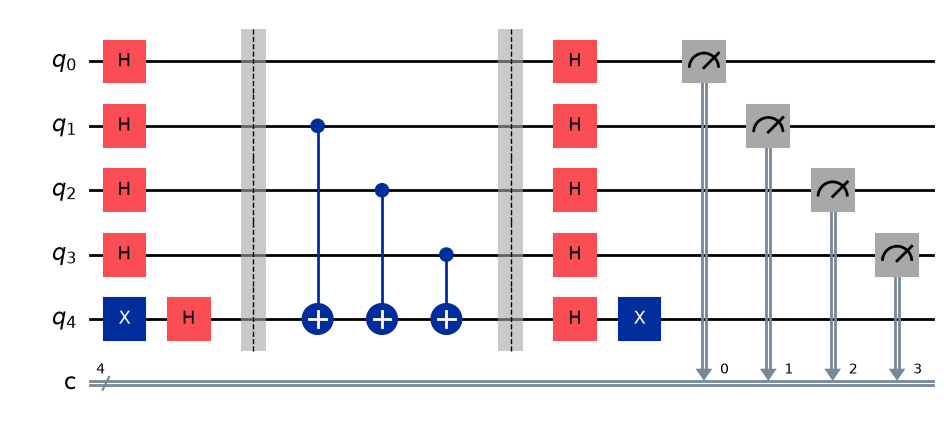

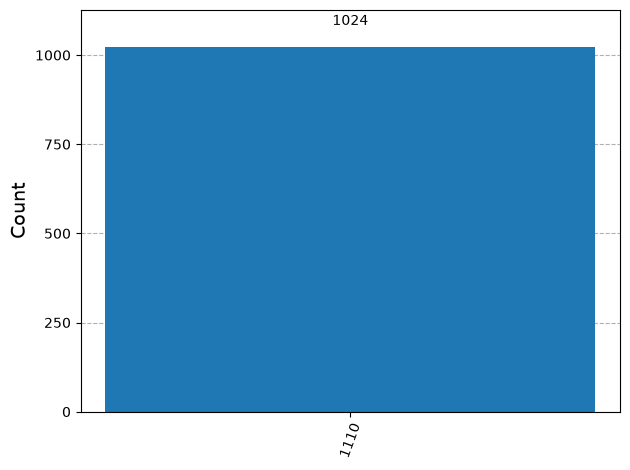

In [6]:
n_qubits = 4
s_int = 14
s_str = to_bitstring(s_int, n_qubits)
print(f's = {s_int} (bitstring = {s_str})')

bv_circuit = bernstein_vazirani(s_int, n=n_qubits)
display(bv_circuit.draw(output='mpl'))

answer = execute(bv_circuit, backend=simulator, shots=1024).result().get_counts()
print(answer)
plot_histogram(answer)

The measured string is the binary representation of the hidden integer.

### 6.3 Phase-oracle variant (no ancilla)

Same algorithm with the Z-gate oracle, for $a = 7$ on $n = 3$ qubits (`111`). Only $n$ qubits are needed.

#### Code walkthrough: phase-oracle variant

- `bernstein_vazirani(7, n=3, kind='phase')` uses secret $a = 7$ (`'111'`) on 3 qubits, with the **Z-gate oracle** and **no ancilla**. This is a cleaned-up version of the original `022_03b` script, which also used an ancilla even though the Z oracle doesn't need one.
- In the drawing, each qubit has `H – Z – H`. A useful identity is $HZH = X$, so the circuit simply flips every qubit where $s_i = 1$. The input qubits are never entangled with each other. The "quantumness" lies in the fact that we did not know *which* qubits to flip: the oracle told us in a single query.
- `max(counts, key=counts.get)` picks the most frequent bit string. On a perfect simulator there is only one, but writing it this way also works on noisy hardware.
- `int(..., 2)` converts the binary string to an integer, which gives `7`.

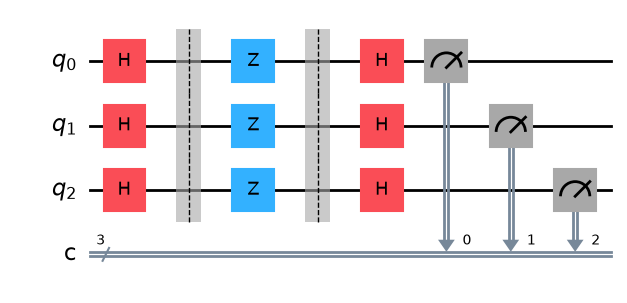

{'111': 1024}
Recovered a = 7


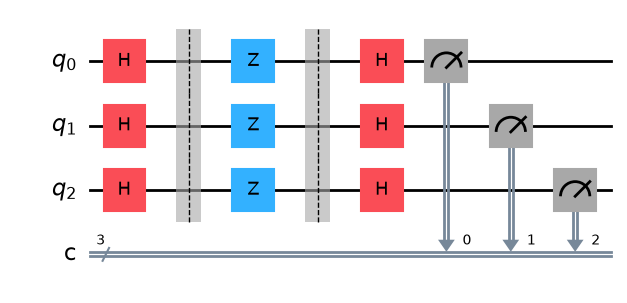

In [7]:
phase_circuit = bernstein_vazirani(7, n=3, kind='phase')
display(phase_circuit.draw(output='mpl'))

counts = execute(phase_circuit, backend=simulator, shots=1024).result().get_counts()
print(counts)
print('Recovered a =', int(max(counts, key=counts.get), 2))

`111` in base 2 = 7, so $a = 7$, as expected.

### 6.4 Statevector check

Removing the measurement, we can confirm that just before measuring the input register is in the basis state $\lvert s \rangle$ with probability 1 — for both oracle types.

#### Code walkthrough: statevector check

So far we have only *sampled* the circuit. Here we look at the **exact** final state to confirm the mathematics.

- The loop runs the same check for both oracle types with secret `'1011'`.
- `measure=False` builds the circuit without measurements. A `Statevector` describes the state *before* measurement, so measurements must not be in the circuit.
- `Statevector(circuit)` simulates the circuit exactly by multiplying the gate matrices. The result is a list of $2^{\#\text{qubits}}$ complex amplitudes.
- `.probabilities_dict()` turns amplitudes into probabilities $|\text{amplitude}|^2$, keyed by basis-state label.
- The dict comprehension keeps only entries with probability above $10^{-9}$ (the others are floating-point zeros). It also converts numpy types to plain `str`/`float` so the output is easy to read.
- **Result:** each oracle gives a single entry with probability `1.0`. The state really *is* $\lvert s \rangle$, not merely "mostly $\lvert s \rangle$".
- For the CNOT oracle the label has 5 characters. The left-most one is the ancilla, which is `0` thanks to the clean-up step. **Try it:** delete the two clean-up lines (`qc.h(n)`, `qc.x(n)`) in `bernstein_vazirani`, re-run, and you will see two entries of 0.5. The ancilla is left in $\lvert - \rangle$, while the input register still reads `1011`.

In [8]:
for kind in ('cnot', 'phase'):
    sv = Statevector(bernstein_vazirani('1011', kind=kind, measure=False))
    probs = sv.probabilities_dict()
    print(f'{kind:5s} oracle ->', {str(k): round(float(v), 6) for k, v in probs.items() if v > 1e-9})

cnot  oracle -> {'01011': 1.0}
phase oracle -> {'1011': 1.0}


For the CNOT version the label includes the ancilla as the left-most bit (`0` after clean-up), so `01011` corresponds to $s = 1011$.

### 6.5 Classical vs. quantum query count

To make the comparison concrete, here is the classical $n$-query strategy from Section 2 running against a counting oracle, next to the single quantum query, for random secrets of increasing size.

#### Code walkthrough: classical vs. quantum query count

This cell puts the classical algorithm of Section 2 and the quantum algorithm side by side, and **counts oracle calls**.

**`ClassicalOracle`: a classical black box**
- `__init__` stores the secret as an integer (`int(s, 2)`). The leading underscore in `_s` is a Python convention meaning "private, don't peek".
- `__call__` makes the object usable like a function: `oracle(x)`. Each call increments `self.queries`, so we can count exactly how many times the box was used.
- `bin(self._s & x).count('1') % 2` computes $s \cdot x \bmod 2$. First the bitwise AND, then count the 1s, then take the parity.

**`classical_bv(oracle, n)`: the best classical strategy**
- Queries the box with `1 << i` for $i = 0 \dots n-1$, i.e. the numbers `0…001`, `0…010`, `0…100`, … Each such input has a single 1, so the answer is exactly bit $s_i$.
- The bits are collected from bit 0 upwards and then reversed, so the result is printed most-significant bit first, like `s`.

**The comparison loop**
- `np.random.default_rng(42)` is a random generator with a fixed **seed**, so you get the same "random" secrets every time you run the notebook.
- For each size $n \in \{2, 4, 8, 12\}$:
  - draw a random secret `s`,
  - solve it classically and record `oracle.queries`,
  - solve it with one shot of the quantum circuit. `next(iter(q_counts))` takes the only key of the counts dictionary.
- **Columns:** `secret` is the true value, `classical` and `quantum` are the recovered answers (they always agree), and `#q` is the number of oracle queries: **$n$ classically versus always 1 quantumly**.

> Note: simulating the quantum circuit on a laptop gets exponentially harder as $n$ grows. That is a cost of *simulating* quantum hardware on classical hardware, not of the algorithm itself.

In [9]:
class ClassicalOracle:
    def __init__(self, s):
        self._s = int(s, 2)
        self.queries = 0

    def __call__(self, x):
        self.queries += 1
        return bin(self._s & x).count('1') % 2


def classical_bv(oracle, n):
    # Query with 2^0, 2^1, ..., 2^(n-1); each answer reveals one bit of s.
    bits = [oracle(1 << i) for i in range(n)]
    return ''.join(str(b) for b in reversed(bits))


rng = np.random.default_rng(42)
print(f"{'n':>3} {'secret':>14} {'classical':>14} {'#q':>4} {'quantum':>14} {'#q':>4}")
for n in (2, 4, 8, 12):
    s = ''.join(rng.choice(['0', '1'], size=n))
    oracle = ClassicalOracle(s)
    c_ans = classical_bv(oracle, n)
    q_counts = execute(bernstein_vazirani(s), backend=simulator, shots=1).result().get_counts()
    q_ans = next(iter(q_counts))
    print(f'{n:>3} {s:>14} {c_ans:>14} {oracle.queries:>4} {q_ans:>14} {1:>4}')

  n         secret      classical   #q        quantum   #q
  2             01             01    2             01    1
  4           1001           1001    4           1001    1
  8       01001111       01001111    8       01001111    1
 12   111010100111   111010100111   12   111010100111    1


## 7. Running on real hardware

On a noisy device the outcome is no longer deterministic: gate errors (especially the CNOTs and the SWAPs inserted by routing) and readout errors spread probability over other bit strings, though $s$ should still be the most likely result.

The cell below runs only if `IBM_QUANTUM_TOKEN` is set; it picks the least-busy device with enough qubits and runs the circuit with the Runtime `SamplerV2` primitive. Results below 1% of the shots are grouped as `other_bitstrings` for readability.

#### Code walkthrough: real hardware

This cell only runs if you have an IBM Quantum account token. Otherwise it prints a message and skips. It reuses `bv_circuit` (the $s = 14$ circuit from 6.2), so run the cells above first.

1. **Choose a device:** `get_backend('least_busy', token=..., min_num_qubits=bv_circuit.num_qubits)` connects to IBM Quantum and picks the real device with the shortest job queue that has at least 5 qubits.
2. **Transpile:** real chips only support a small set of native gates (for example `rz`, `sx`, `x`, `ecr`/`cz`), and each qubit can only interact with its neighbours. `transpile(...)` rewrites our circuit into native gates, maps our qubits onto physical qubits, and inserts SWAPs where needed. `optimization_level=3` is the most aggressive optimisation (fewer gates mean less noise). The output is called an **ISA circuit** (Instruction Set Architecture), which the runtime requires.
3. **Run:** `SamplerV2` is IBM's *primitive* for "run circuits and give me measurement samples". `.run([isa_circuit], shots=shots)` submits a list of circuits (called PUBs) as a single job in the cloud queue. `job.job_id()` lets you look it up later on the IBM Quantum dashboard. `job.result()` **waits** until the job finishes, which can take from seconds to hours depending on the queue.
4. **Read the counts:** `job.result()[0]` is the result for the first (only) circuit. `.data.c` is the classical register, which Qiskit named `c` automatically when we wrote `QuantumCircuit(n + 1, n)`. `.get_counts()` returns the familiar dictionary.
5. **Filter for readability:** noise spreads a little probability over many wrong bit strings. Any string seen in fewer than 1% of shots (`threshold`) is lumped into `other_bitstrings`, so the histogram stays readable.
6. **Success probability:** `hw_answer.get(s_str, 0) / shots` is the fraction of shots that returned the correct secret. Expect it to be clearly below 1.0 because of gate and readout errors, but `1110` should still be the tallest bar.

In [10]:
if not IBM_QUANTUM_TOKEN:
    print('IBM_QUANTUM_TOKEN not set - skipping the real-hardware run.')
else:
    from qiskit import transpile
    from qiskit_ibm_runtime import SamplerV2 as Sampler

    hw_backend = get_backend('least_busy', token=IBM_QUANTUM_TOKEN,
                             min_num_qubits=bv_circuit.num_qubits)
    shots = 1024
    isa_circuit = transpile(bv_circuit, backend=hw_backend, optimization_level=3)
    job = Sampler(mode=hw_backend).run([isa_circuit], shots=shots)
    print('Job ID:', job.job_id())
    hw_answer = job.result()[0].data.c.get_counts()

    threshold = int(0.01 * shots)
    filtered = {k: v for k, v in hw_answer.items() if v >= threshold}
    filtered['other_bitstrings'] = sum(v for v in hw_answer.values() if v < threshold)
    print(filtered)
    print(f"P(s = {s_str}) = {hw_answer.get(s_str, 0) / shots:.3f}")
    display(plot_histogram(filtered))

IBM_QUANTUM_TOKEN not set - skipping the real-hardware run.


## 8. Summary

| | Classical | Quantum (BV) |
|---|---|---|
| Oracle queries | $n$ | **1** |
| Qubits | – | $n+1$ (CNOT oracle) or $n$ (phase oracle) |
| Gates | – | $\mathcal{O}(n)$ |
| Success probability (ideal) | 1 | 1 (deterministic) |

Key ideas: superposition to query all inputs at once, **phase kickback** to turn $f(x)$ into a phase, and **interference** via the final Hadamards to concentrate all amplitude on $\lvert s \rangle$.

## References

[1] E. Bernstein and U. Vazirani, "Quantum Complexity Theory", *SIAM Journal on Computing* 26(5), 1411–1473 (1997). doi:10.1137/S0097539796300921

[2] S. D. Fallek, C. D. Herold, B. J. McMahon, K. M. Maller, K. R. Brown, J. M. Amini, "Transport implementation of the Bernstein-Vazirani algorithm with ion qubits", *New J. Phys.* 18, 083030 (2016).

[3] Qiskit Textbook, "Bernstein-Vazirani Algorithm": https://github.com/Qiskit/textbook/blob/main/notebooks/ch-algorithms/bernstein-vazirani.ipynb

[4] Qiskit video, "Bernstein-Vazirani algorithm": https://youtu.be/sqJIpHYl7oo